In [1]:
pip install causalml -q

In [2]:
import numpy as np, pandas as pd
from google.colab import drive
pd.set_option('display.max_columns',None)
drive.mount('/content/drive')
import warnings
warnings.filterwarnings('ignore')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
!unzip /content/drive/MyDrive/ihdp_dataset.zip

Archive:  /content/drive/MyDrive/ihdp_dataset.zip
replace ihdp_data.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: ihdp_data.csv           


# For a real RCT, the probability of getting assigned to treatment and control should be independent of the covariates. Otherwise, serious confounding can occur.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from causalml.propensity import ElasticNetPropensityModel

plt.style.use("fivethirtyeight")

In [5]:
ihdp = pd.read_csv('ihdp_data.csv')
ihdp['w'] = ihdp['treatment'].apply(lambda x : 1 if x == True else 0)
ihdp['tau'] = ihdp['mu1'] - ihdp['mu0']

feat_cols = [x for x in ihdp.columns if x.startswith('x')]

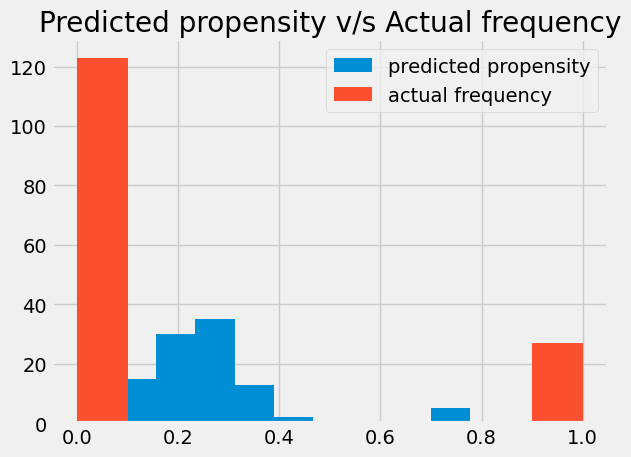

In [6]:
X = ihdp[feat_cols].to_numpy()
y = ihdp[['y_factual']].to_numpy().reshape(-1)
w = ihdp[['w']].to_numpy().reshape(-1)
tau = ihdp[['tau']].to_numpy().reshape(-1)

X_train, X_test, y_train, y_test, w_train, w_test, tau_train, tau_test = train_test_split(X,
                                                                                          y,
                                                                                          w,
                                                                                          tau,
                                                                                          test_size=0.2,
                                                                                          random_state=42)


pm = ElasticNetPropensityModel(Cs=np.logspace(0, 3, 8), random_state=42)
pm.fit(X_train, np.array(w_train).reshape(-1))

p_train = pm.predict(X_train)
p_test = pm.predict(X_test)

plt.hist(p_test,label='predicted propensity')
plt.hist(w_test,label='actual frequency')
plt.title('Predicted propensity v/s Actual frequency')
plt.legend()
plt.tight_layout()
plt.show()








<p> We can check if the propensity as estimated by ElasticNet model is identical for treatment and control groups </p>

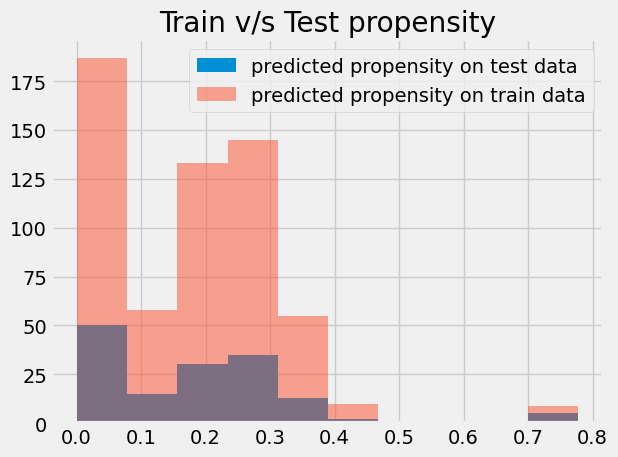

In [7]:
plt.hist(pm.predict(X_test),label='predicted propensity on test data')
plt.hist(pm.predict(X_train),alpha=0.5,label='predicted propensity on train data')
plt.title('Train v/s Test propensity')
plt.legend()
plt.tight_layout()
plt.show()

[]

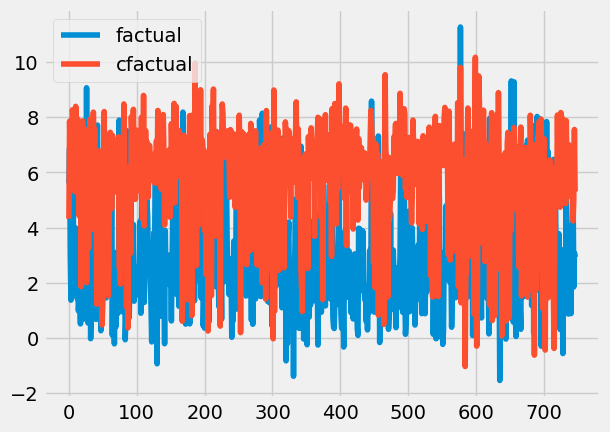

In [8]:
ihdp['y_factual'].plot(label='factual')
ihdp['y_cfactual'].plot(label='cfactual')
plt.legend()
plt.plot()

[]

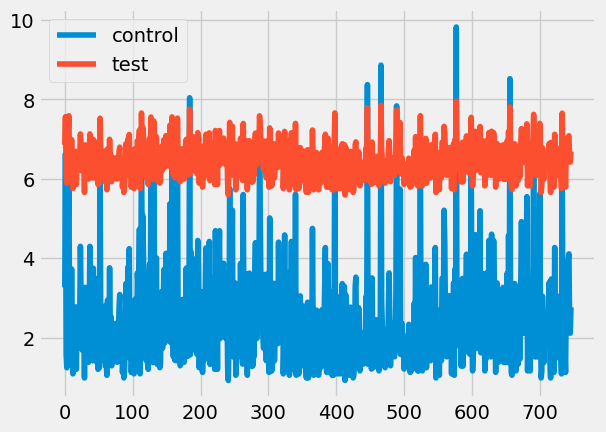

In [9]:
ihdp['mu0'].plot(label='control',linestyle='-')
ihdp['mu1'].plot(label='test',linestyle='-')
plt.legend()
plt.plot()

In [10]:
ihdp.head()

,treatment,y_factual,y_cfactual,mu0,mu1,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,x14,x15,x16,x17,x18,x19,x20,x21,x22,x23,x24,x25,w,tau
0,True,5.599916,4.318780,3.268256,6.854457,-0.528603,-0.343455,1.128554,0.161703,-0.316603,1.295216,1,0,1,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,0,1,3.586200
1,False,6.875856,7.856495,6.636059,7.562718,-1.736945,-1.802002,0.383828,2.244320,-0.629189,1.295216,0,0,0,1,0,0,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0.926659
2,False,2.996273,6.633952,1.570536,6.121617,-0.807451,-0.202946,-0.360898,-0.879606,0.808706,-0.526556,0,0,0,1,0,0,0,2,0,1,0,1,1,0,0,0,0,0,0,0,4.551081
3,False,1.366206,5.697239,1.244738,5.889125,0.390083,0.596582,-1.850350,-0.879606,-0.004017,-0.857787,0,0,0,0,0,1,1,2,0,1,0,1,1,0,0,0,0,0,0,0,4.644387
4,False,1.963538,6.202582,1.685048,6.191994,-1.045229,-0.602710,0.011465,0.161703,0.683672,-0.360940,1,0,0,0,0,1,1,1,0,1,1,1,1,0,0,0,0,0,0,0,4.506946


# Trying four different model classes
1. T-Learner
2. X-Learner
3. R-Learner
4. Causal RF

In [11]:
from causalml.inference.meta.tlearner import BaseTRegressor
from causalml.inference.meta import BaseXRegressor, BaseRRegressor
from causalml.inference.tree import CausalRandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor


learners = {
    "T-Learner": BaseTRegressor(learner=GradientBoostingRegressor(random_state=42)),
    "X-Learner": BaseXRegressor(learner=GradientBoostingRegressor(random_state=42)),
    "R-Learner": BaseRRegressor(learner=GradientBoostingRegressor(random_state=42)),
    "Causal RF": CausalRandomForestRegressor(random_state=42),
}


def fit_all(learners, X, w, y, p):
  for label, model in learners.items():
    print(f'Fitting {label}...')
    if label.startswith('X') or label.startswith('R'):
      model.fit(X=X,treatment=w,y=y,p=p)
    else:
      model.fit(X=X,treatment=w,y=y)

def predict_all(learners, X, p):
    out = {}
    for label, model in learners.items():
        if label.startswith('X'):
            out[label] = model.predict(X=X, p=p).flatten()
        else:
            out[label] = model.predict(X).flatten()
    return out

ERROR:duecredit:Failed to import duecredit due to No module named 'duecredit'


In [12]:
fit_all(learners, X_train, w_train, y_train, p_train)

Fitting T-Learner...
Fitting X-Learner...
Fitting R-Learner...
Fitting Causal RF...


In [13]:
print(f"Real ATE: {tau_train.mean():.4}")

ate_t,_,_ = learners["T-Learner"].estimate_ate(X=X_train, treatment=w_train, y=y_train,pretrain=True)
print(f"T-Learner ATE: {ate_t.item():.4}")

ate_x,_,_ = learners["X-Learner"].estimate_ate(X=X_train, treatment=w_train, y=y_train,p=p_train, pretrain=True)
print(f'X-Learner ATE: {ate_x.item():.4}')

ate_r,_,_ = learners["R-Learner"].estimate_ate(X=X_train, treatment=w_train, y=y_train,p=p_train, pretrain=True)
print(f'R-Learner ATE: {ate_r.item():.4}')

cate_cf = learners["Causal RF"].predict(X=X_train)
print(f"Causal RF Learner: {cate_cf.mean():.4}")

Real ATE: 4.008
T-Learner ATE: 4.018
X-Learner ATE: 4.177
R-Learner ATE: 6.559
Causal RF Learner: 6.363


In [14]:
from causalml.metrics import auuc_score, plot_gain, plot_toc

In [15]:
fit_all(learners, X_test, w_test,
        y_test, p_test)
cate_val = predict_all(learners, X_test, p_test)

df_test = pd.DataFrame({"y": y_test, "w": w_test, **cate_val})

print(auuc_score(df_test, outcome_col="y", treatment_col="w",
                 return_ci=True, random_state=42).round(3))

Fitting T-Learner...
Fitting X-Learner...
Fitting R-Learner...
Fitting Causal RF...
T-Learner    0.636
X-Learner    0.609
R-Learner    0.556
Causal RF    0.505
dtype: float64


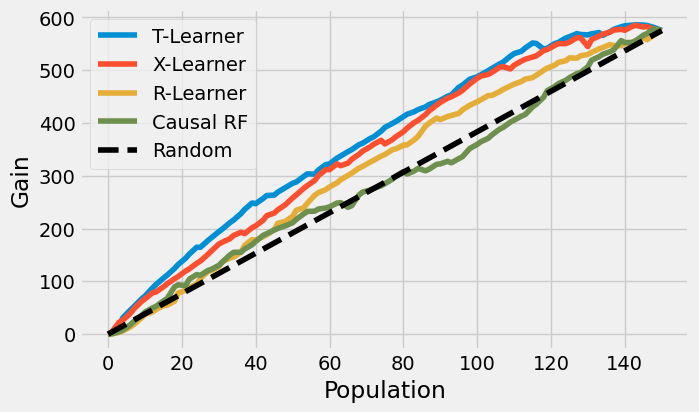

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.2))
plot_gain(df_test, outcome_col="y", treatment_col="w", ax=ax)

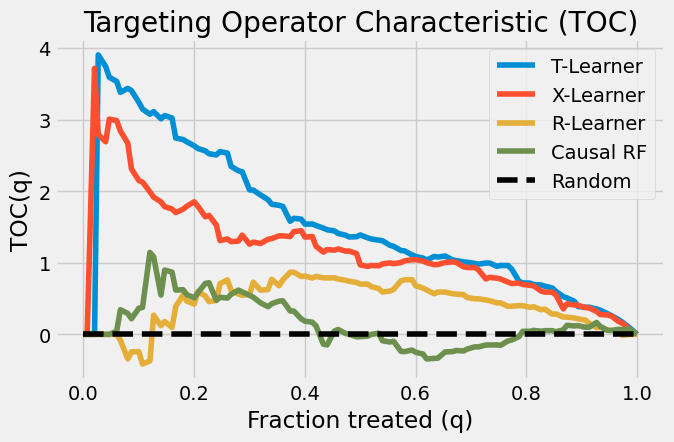

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.2))
plot_toc(df_test, outcome_col="y", treatment_col="w", ax=ax)
plt.show()

# Sensitivity Analysis

In [18]:
from causalml.metrics.sensitivity import Sensitivity

X = ihdp[feat_cols]
y = ihdp[['y_factual']]
w = ihdp[['w']]
tau = ihdp[['tau']]


X_train, X_test, y_train, y_test, w_train, w_test, tau_train, tau_test = train_test_split(X,
                                                                                          y,
                                                                                          w,
                                                                                          tau,
                                                                                          test_size=0.2,
                                                                                          random_state=42)

df_s = X_train.assign(treatment=w_train, outcome=y_train, p=p_train)
sens = Sensitivity(df=df_s, inference_features=list(X_train.columns),
                   p_col="p", treatment_col="treatment",
                   outcome_col="outcome",
                   learner=BaseXRegressor(learner=GradientBoostingRegressor(random_state=42)))

print(sens.sensitivity_analysis(
    methods=["Placebo Treatment", "Random Cause", "Subset Data"],
    sample_size=0.5).to_string())

                          Method       ATE   New ATE  New ATE LB  New ATE UB
0              Placebo Treatment  4.176549 -0.160684   -0.340504    0.019136
1                   Random Cause  4.176549  4.072808    3.961055    4.184562
2  Subset Data(sample size @0.5)  4.176549  4.047923    3.913492    4.182354
